# 02 · Limpieza y preparación

Limpieza mínima del texto (sin borrar el estilo de escritura), control de duplicados y de fuga, y división **entrenamiento / validación / prueba**. La prueba (200 quejas) quedó fijada al generar el corpus y solo se usa una vez, en `05_evaluacion`.

In [1]:
# Preparación del entorno. En Colab, el repositorio vive en Google Drive para que los 5 notebooks compartan
# datos, modelos y resultados entre sesiones.
import os, sys, json, time, platform, shutil
EN_COLAB = "google.colab" in sys.modules
REPO = "github.com/jobedon/triajeia-isp.git"   # repositorio privado
if EN_COLAB:
    from google.colab import drive, userdata
    drive.mount("/content/drive")
    DESTINO = "/content/drive/MyDrive/triajeia-isp"
    ZIP = "/content/drive/MyDrive/triajeia-isp.zip"
    try:
        TOKEN = userdata.get("GITHUB_TOKEN")      # Secretos de Colab (🔑): token de solo lectura
    except Exception:
        TOKEN = None
    if TOKEN:
        url = f"https://x-access-token:{TOKEN}@{REPO}"
        if not os.path.exists(f"{DESTINO}/.git"):
            r = os.system(f"git clone -q {url} {DESTINO} > /dev/null 2>&1")
        else:
            r = os.system(f"git -C {DESTINO} pull -q {url} main > /dev/null 2>&1")
        print("Código actualizado desde GitHub" if r == 0 else "No se pudo usar GitHub; se usa la copia de Drive")
    elif not os.path.exists(DESTINO) and os.path.exists(ZIP):
        shutil.unpack_archive(ZIP, "/content/drive/MyDrive")
        print("Código extraído de triajeia-isp.zip")
    if not os.path.exists(f"{DESTINO}/config.yaml"):
        raise FileNotFoundError("No se encontró el código. Agregue el secreto GITHUB_TOKEN o suba triajeia-isp.zip a la raíz de Drive.")
    os.chdir(DESTINO)
    os.system('pip install -q "scikit-learn==1.6.1" "optuna>=4" "fairlearn>=0.12"')
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
PRUEBA_RAPIDA = os.environ.get("PRUEBA_RAPIDA", "0") == "1"   # solo para verificar el código; sus números no se usan
print("Directorio:", os.getcwd(), "| Colab:", EN_COLAB, "| Prueba rápida:", PRUEBA_RAPIDA)

Mounted at /content/drive
Código actualizado desde GitHub
Directorio: /content/drive/MyDrive/triajeia-isp | Colab: True | Prueba rápida: False


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from src.utils import cargar_config, cargar_json, fijar_semilla, guardar_json

cfg = cargar_config()
SEMILLA = cfg["semilla"]
fijar_semilla(SEMILLA)
FIG, MET = "results/figures", "results/metrics"
os.makedirs(FIG, exist_ok=True); os.makedirs(MET, exist_ok=True); os.makedirs("models", exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
GRANATE = "#791632"

def guardar_fig(nombre):
    plt.tight_layout()
    plt.savefig(f"{FIG}/{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()

def entorno():
    e = {"colab": EN_COLAB, "prueba_rapida": PRUEBA_RAPIDA, "python": platform.python_version(),
         "sklearn": sklearn.__version__, "pandas": pd.__version__, "fecha": time.strftime("%Y-%m-%d %H:%M")}
    try:
        import torch
        e["torch"] = torch.__version__
        e["gpu"] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
    except ImportError:
        e["gpu"] = None
    return e
NB = "02"

In [3]:
from src.data_processing import cargar_corpus, dividir, limpiar_texto
df = cargar_corpus(cfg["datos"]["corpus"])
df["texto"] = df["queja"].map(limpiar_texto)
cambios = df[df["texto"] != df["queja"]]
print(f"Textos modificados por la limpieza: {len(cambios)} de {len(df)}")
cambios[["queja", "texto"]].head(5)

19:49:58 | INFO | src.data_processing | Corpus cargado: 1500 quejas ({'entrenamiento': 1300, 'prueba': 200})
INFO:src.data_processing:Corpus cargado: 1500 quejas ({'entrenamiento': 1300, 'prueba': 200})


Textos modificados por la limpieza: 226 de 1500


,queja,texto
0,"@ISP hace 4 dias q espero al tecnico y nada, n...","@isp hace 4 dias q espero al tecnico y nada, n..."
2,"@ISP ve, en el barrio San Sebastián un camión ...","@isp ve, en el barrio San Sebastián un camión ..."
8,@ISP desde ayer hay un poste suyo medio tumbad...,@isp desde ayer hay un poste suyo medio tumbad...
16,@ISP ase 5 dias que el cable de la fibra esta ...,@isp ase 5 dias que el cable de la fibra esta ...
26,"@ISP q tal servicio eh, ayer me llega la factu...","@isp q tal servicio eh, ayer me llega la factu..."


**Decisión:** no se quitan tildes, mayúsculas sostenidas ni faltas de ortografía en el texto guardado. El vectorizador pasa a minúsculas y los n-gramas de caracteres toleran las erratas. Así el modelo aprende a manejar todas las formas de escribir, que es un requisito de equidad (Semana 4).

In [4]:
dup = df["texto"].str.lower().duplicated(keep=False)
print("Duplicados exactos:", int(dup.sum()))
train, val, test = dividir(df, "categoria", cfg["datos"]["fraccion_validacion"], SEMILLA)
print("Entrenamiento:", len(train), "· Validación:", len(val), "· Prueba:", len(test))

Duplicados exactos: 0
Entrenamiento: 1105 · Validación: 195 · Prueba: 200


In [5]:
def tejas(t, n=4):
    w = t.lower().split(); return {" ".join(w[i:i + n]) for i in range(max(1, len(w) - n + 1))}
st = [tejas(t) for t in test["texto"]]; sr = [tejas(t) for t in pd.concat([train, val])["texto"]]
maxj = [max(len(a & b) / len(a | b) for b in sr) for a in st]
print(f"Similitud máxima (Jaccard de 4-gramas) de cada queja de prueba con el entrenamiento: "
      f"mediana {np.median(maxj):.2f}, máximo {max(maxj):.2f}")

Similitud máxima (Jaccard de 4-gramas) de cada queja de prueba con el entrenamiento: mediana 0.05, máximo 0.43


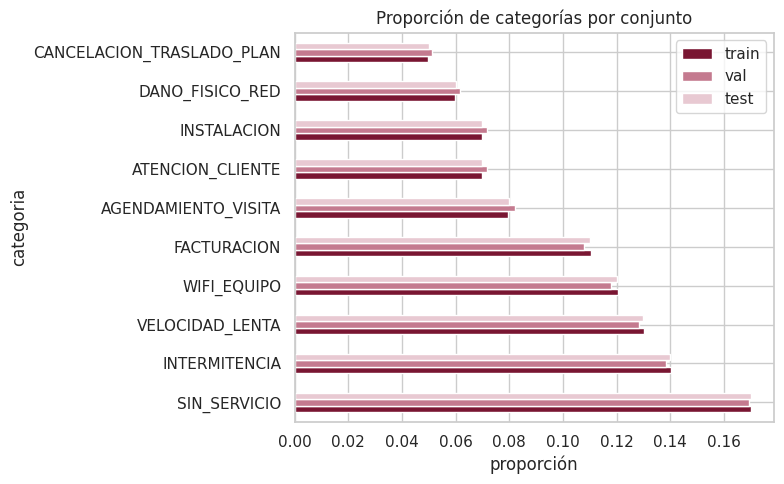

In [6]:
dist = pd.DataFrame({n: d["categoria"].value_counts(normalize=True) for n, d in [("train", train), ("val", val), ("test", test)]})
dist.plot.barh(figsize=(8, 5), color=[GRANATE, "#c47a8f", "#e8c9d2"])
plt.title("Proporción de categorías por conjunto"); plt.xlabel("proporción")
guardar_fig("02_estratificacion")

In [7]:
os.makedirs(cfg["datos"]["procesados"], exist_ok=True)
cols = ["id", "texto", "categoria", "area_atencion", "prioridad", "registro", "region", "canal", "dificultad"]
for nombre, d in [("train", train), ("val", val), ("test", test)]:
    d[cols].to_csv(f"{cfg['datos']['procesados']}/{nombre}.csv", index=False)
guardar_json({"n": {"train": len(train), "val": len(val), "test": len(test)}, "duplicados_exactos": int(dup.sum()),
              "jaccard_max_test_vs_train": float(max(maxj)), "textos_modificados": int(len(cambios))},
             f"{MET}/02_preprocesamiento.json")

PosixPath('/content/drive/MyDrive/triajeia-isp/results/metrics/02_preprocesamiento.json')

In [8]:
# Guarda el registro del entorno. En Colab, los resultados ya quedaron en Google Drive
# (MyDrive/triajeia-isp/results y models). Descargue además este notebook con sus salidas:
# Archivo → Descargar → .ipynb, y colóquelo en notebooks/ del repositorio.
guardar_json(entorno(), f"{MET}/entorno_{NB}.json")
print("Listo:", NB)

Listo: 02
